<a href="https://colab.research.google.com/github/2025csnagendrand-beep/DAV-/blob/main/lab_program11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.cluster.hierarchy import dendrogram

In [2]:
students = ['A', 'B', 'C', 'D', 'E', 'F']
marks = [30, 35, 40, 80, 85, 90]

In [3]:
x = np.arange(len(students))
marks_array = np.array(marks)


In [4]:
phases = [
    [[0], [1], [2], [3], [4], [5]],
    [[0, 1], [2], [3], [4], [5]],
    [[0, 1, 2], [3], [4], [5]],
    [[0, 1, 2], [3, 4], [5]],
    [[0, 1, 2], [3, 4, 5]],
    [[0, 1, 2, 3, 4, 5]]
]

In [5]:
titles = [
    "Phase 1: Initial 6 Clusters",
    "Phase 2: Merge A and B",
    "Phase 3: Merge C with AB",
    "Phase 4: Merge D and E",
    "Phase 5: Merge DE with F",
    "Phase 6: Merge ABC and DEF"
]


In [6]:
colors = [
    'blue', 'orange', 'green',
    'red', 'purple', 'brown'
]


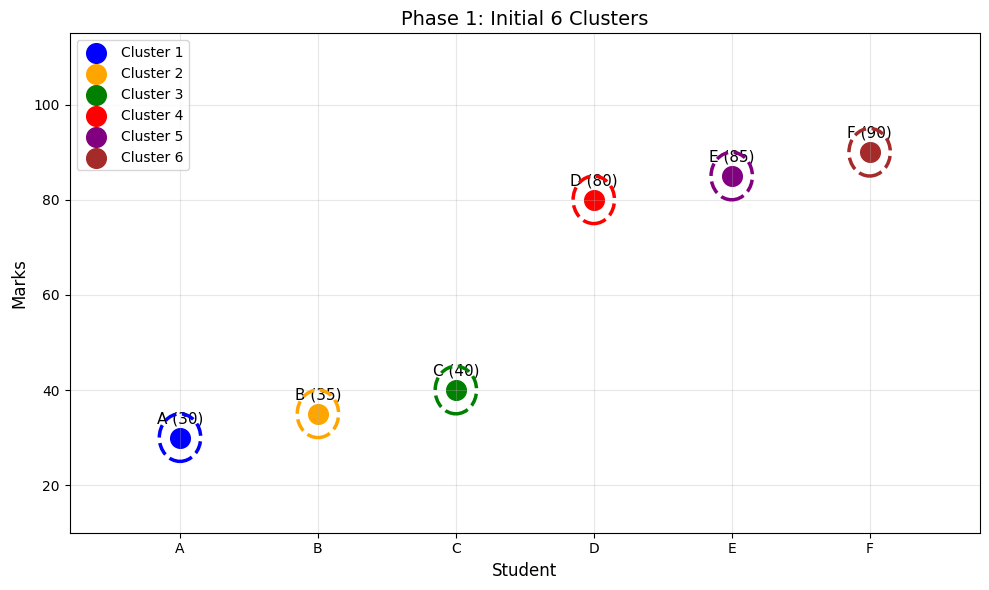

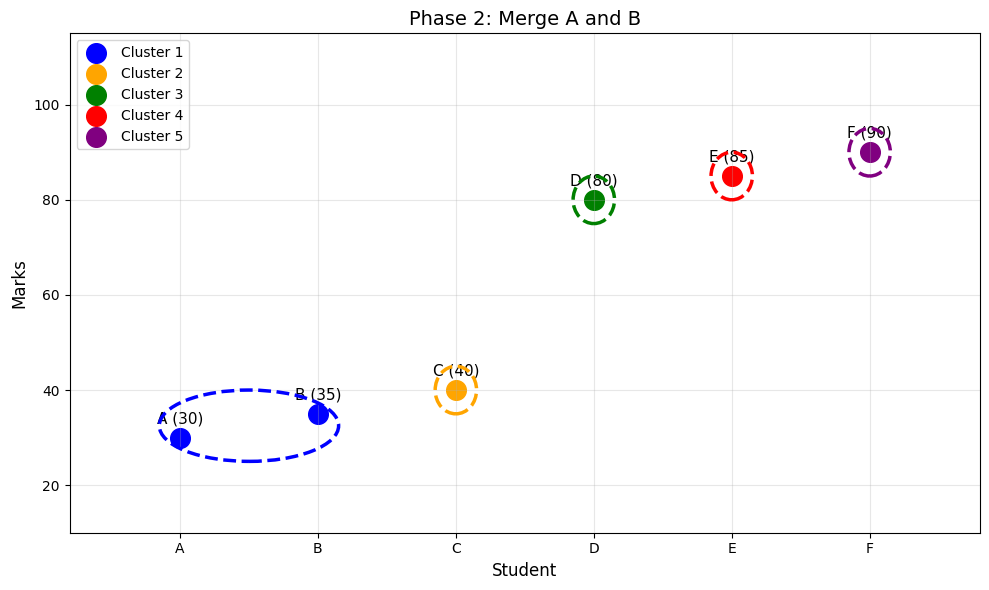

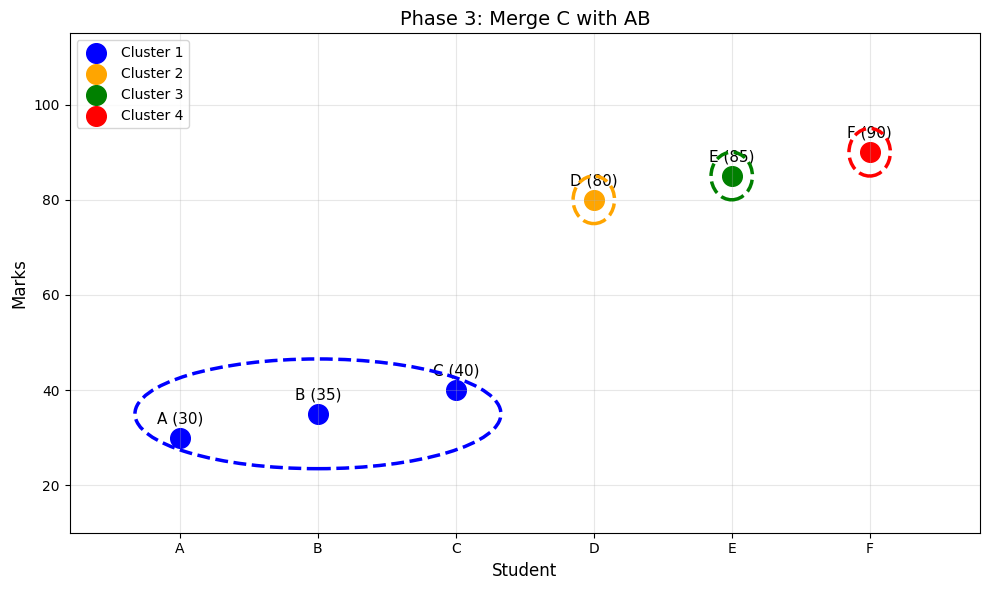

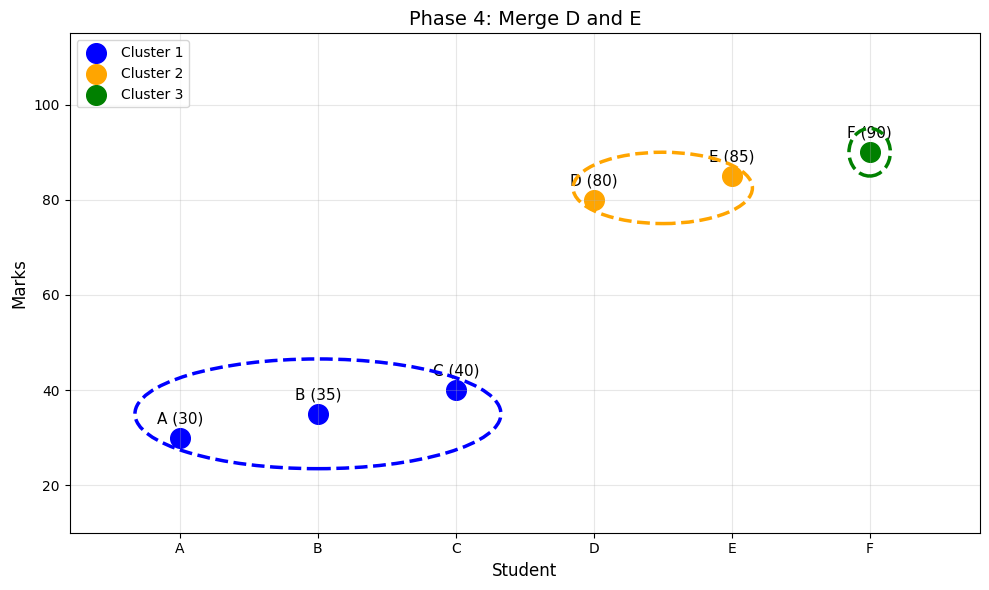

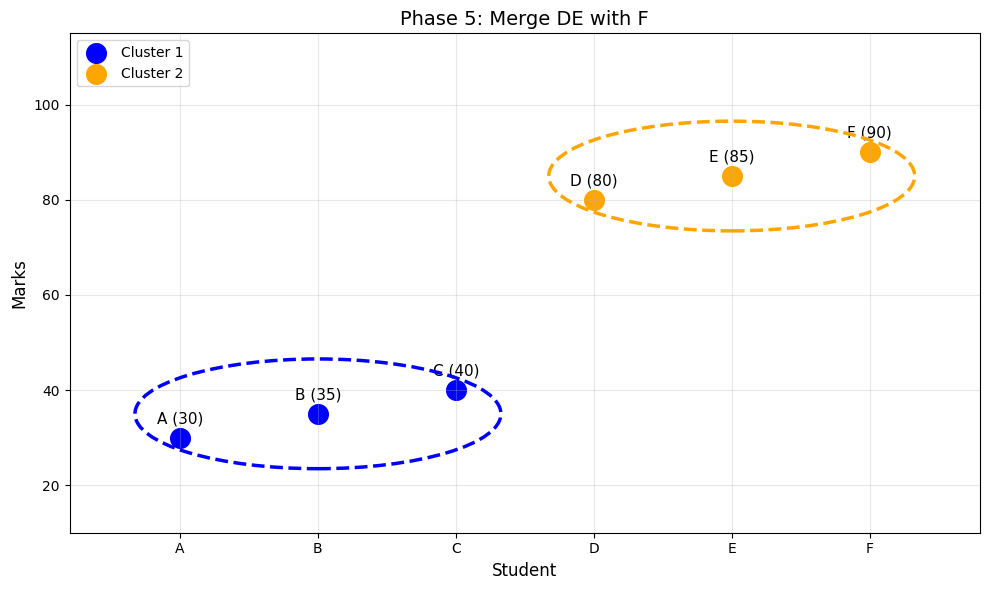

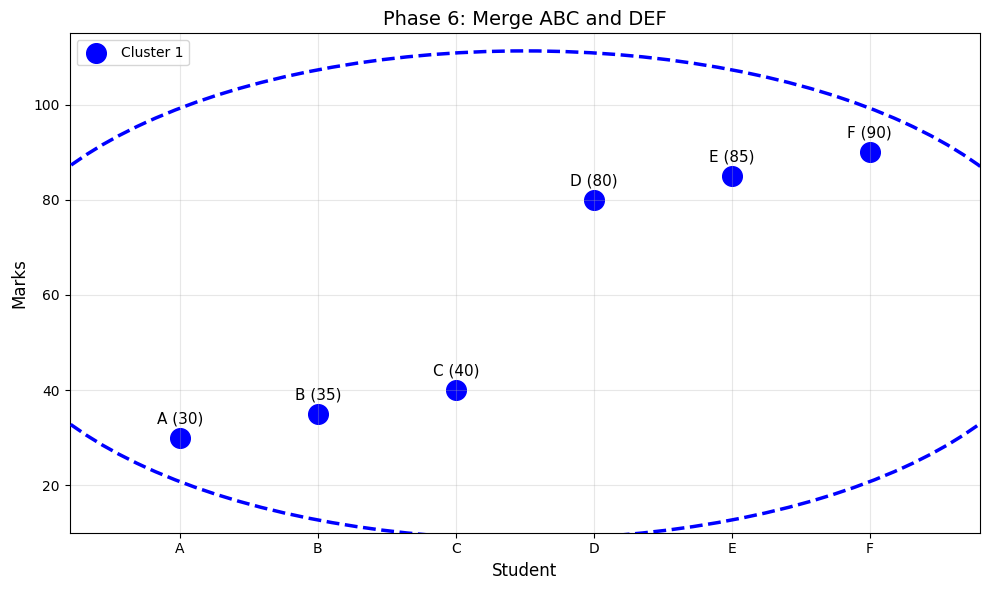

In [8]:
for phase_no, clusters in enumerate(phases):

    fig, ax = plt.subplots(figsize=(10, 6))

    for cluster_no, cluster in enumerate(clusters):

        color = colors[cluster_no]

        cluster_x = x[cluster]
        cluster_y = marks_array[cluster]

        # Plot students

        ax.scatter(
            cluster_x,
            cluster_y,
            color=color,
            s=200,
            label=f'Cluster {cluster_no + 1}'
        )

        # Display student names and marks

        for i in cluster:

            ax.text(
                x[i],
                marks_array[i] + 3,
                f"{students[i]} ({marks[i]})",
                ha='center',
                fontsize=11
            )

        # -----------------------------------
        # Calculate ellipse to cover all points
        # -----------------------------------

        center_x = np.mean(cluster_x)
        center_y = np.mean(cluster_y)

        # Calculate horizontal and vertical radius

        radius_x = max(
            np.max(np.abs(cluster_x - center_x)) + 0.15,
            0.15
        )

        radius_y = max(
            np.max(np.abs(cluster_y - center_y)) + 5,
            5
        )

        # Check the distance of every point from the centre

        distances = np.sqrt(
            ((cluster_x - center_x) / radius_x) ** 2 +
            ((cluster_y - center_y) / radius_y) ** 2
        )

        # Ensure ellipse size can fit all points in cluster

        scale = max(1.0, np.max(distances) * 1.15)

        radius_x *= scale
        radius_y *= scale

        # Draw ellipse

        ellipse = Ellipse(
            (center_x, center_y),
            width=2 * radius_x,
            height=2 * radius_y,
            angle=0,
            facecolor='none',
            edgecolor=color,
            linewidth=2.5,
            linestyle='--',
            zorder=3
        )

        ax.add_patch(ellipse)

    # -----------------------------------
    # Step 4: Improve formatting
    # -----------------------------------

    ax.set_title(titles[phase_no], fontsize=14)

    ax.set_xlabel("Student", fontsize=12)
    ax.set_ylabel("Marks", fontsize=12)

    ax.set_xticks(x)
    ax.set_xticklabels(students)

    ax.set_xlim(-0.8, 5.8)
    ax.set_ylim(10, 115)

    ax.grid(True, alpha=0.3)

    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()

In [9]:
Z = np.array([
    [0, 1, 5, 2],    # A + B
    [6, 2, 5, 3],    # AB + C
    [3, 4, 5, 2],    # D + E
    [8, 5, 5, 3],    # DE + F
    [7, 9, 60, 6]    # ABC + DEF
], dtype=np.float64)


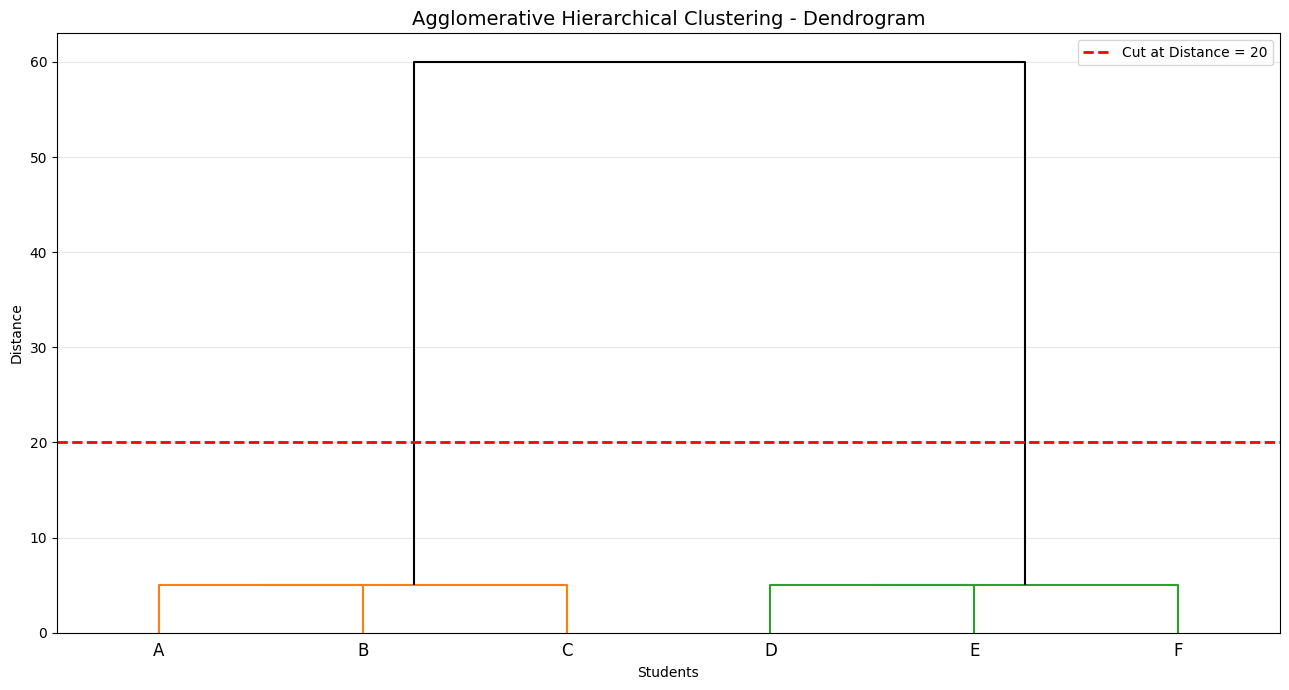

In [10]:
plt.figure(figsize=(13, 7))

dendrogram(
    Z,
    labels=students,
    color_threshold=20,
    above_threshold_color='black'
)

plt.axhline(
    y=20,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Cut at Distance = 20'
)

plt.title(
    'Agglomerative Hierarchical Clustering - Dendrogram',
    fontsize=14
)

plt.xlabel("Students")
plt.ylabel("Distance")

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()